Net(
  (fc1): Linear(in_features=2, out_features=1, bias=False)
)
[Parameter containing:
tensor([[ 1., -1.]], requires_grad=True)]


Epoch 0 - loss: 150.3333282470703
Epoch 1 - loss: 6.120000839233398
Epoch 2 - loss: 36.42483139038086
Epoch 3 - loss: 18.104551315307617
Epoch 4 - loss: 6.065778732299805
Epoch 5 - loss: 10.36883544921875
Epoch 6 - loss: 6.2322306632995605
Epoch 7 - loss: 5.852260589599609
Epoch 8 - loss: 6.088119983673096
Epoch 9 - loss: 5.494865417480469
Epoch 10 - loss: 5.574592590332031
Epoch 11 - loss: 5.536750793457031
Epoch 12 - loss: 5.476492404937744
Epoch 13 - loss: 5.4938530921936035
Epoch 14 - loss: 5.480627536773682
Epoch 15 - loss: 5.477013111114502
Epoch 16 - loss: 5.478647232055664
Epoch 17 - loss: 5.476379871368408
Epoch 18 - loss: 5.476480007171631
Epoch 19 - loss: 5.4764628410339355
Epoch 20 - loss: 5.47619104385376
Epoch 21 - loss: 5.476251602172852
Epoch 22 - loss: 5.476212978363037
Epoch 23 - loss: 5.476190567016602
Epoch 24 - loss: 5.476199626922607
Epoch 25 - loss: 5.476192474365234
Epoch 26 - loss: 5.476190567016602
Epoch 27 - loss: 5.476191997528076
Epoch 28 - loss: 5.47619009

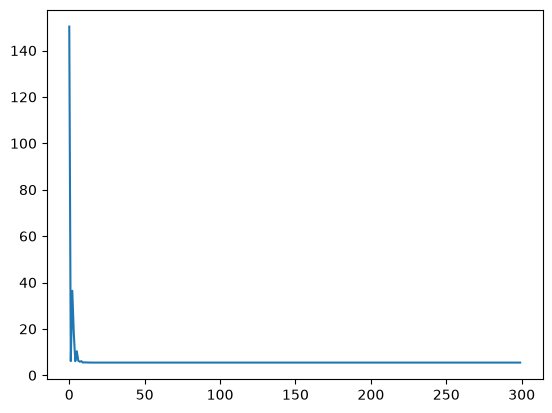

In [1]:
import torch
from torch.autograd import Variable
import torch.nn as nn
import torch.nn.functional as F

import torch.optim as optim
import matplotlib.pyplot as plt

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(2,1,bias=False)
    def forward(self, x):
        x = self.fc1(x)
        return x

net = Net()
print(net)


net.fc1.weight = torch.nn.Parameter(torch.tensor([[1., -1.]], requires_grad=True))

print(list(net.parameters()))

#input = torch.randn(1,2)
#out = net(input)


criterion = nn.MSELoss()
#def criterion(out, label):
#    return ((label - out)**2).mean()


optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.5)
#optimizer = optim.Adam(net.parameters(), lr=0.005)


data = torch.tensor([[1.,3.], [2.,6.], [3.,9.]], dtype=torch.float)
target = torch.tensor([[1.],[5.],[13.]], dtype=torch.float)

hist = []

############## Batch GD based update ##############       
      
for epoch in range(300):   
    optimizer.zero_grad()
    outputs = net(data)
    loss = criterion(outputs, target)
    loss.backward()
    hist.append(loss.detach())
    optimizer.step()
    print("Epoch {} - loss: {}".format(epoch, loss))
####################################################

### Test the trained network ###
for i, current_data in enumerate(data):
    out = net(current_data)  
    print("when x = {}, y = {}".format(current_data, out))
    
plt.plot(hist, label = "training curve")

## Stochastic gradient descent

Both models start from weights `[1, -1]` and train for 300 epochs with learning
rate 0.01 and momentum 0.5. SGD shuffles the points with seed 0 and updates after
each point. Both comparison curves show full-data MSE after each epoch.


In [2]:
batch_net = net
with torch.no_grad():
    batch_final_mse = criterion(batch_net(data), target).item()
batch_hist = [value.item() for value in hist[1:]] + [batch_final_mse]

sgd_net = Net()
sgd_net.fc1.weight = nn.Parameter(torch.tensor([[1., -1.]]))
sgd_optimizer = optim.SGD(sgd_net.parameters(), lr=0.01, momentum=0.5)
shuffle_generator = torch.Generator().manual_seed(0)
sgd_hist = []
sgd_updates = 0

for epoch in range(300):
    for index in torch.randperm(len(data), generator=shuffle_generator).tolist():
        X = data[index:index + 1]
        Y = target[index:index + 1]
        sgd_optimizer.zero_grad()
        outputs = sgd_net(X)
        loss = criterion(outputs, Y)
        loss.backward()
        sgd_optimizer.step()
        sgd_updates += 1
    with torch.no_grad():
        epoch_mse = criterion(sgd_net(data), target).item()
    sgd_hist.append(epoch_mse)
    if epoch == 0 or (epoch + 1) % 50 == 0:
        print("SGD epoch {} - full-data MSE: {:.6f}".format(epoch + 1, epoch_mse))

assert sgd_updates == 300 * len(data)
print("SGD updates:", sgd_updates)


SGD epoch 1 - full-data MSE: 50.978275
SGD epoch 50 - full-data MSE: 59.053577
SGD epoch 100 - full-data MSE: 45.657497
SGD epoch 150 - full-data MSE: 98.223198
SGD epoch 200 - full-data MSE: 10.239625
SGD epoch 250 - full-data MSE: 22.272635
SGD epoch 300 - full-data MSE: 5.776175
SGD updates: 900


Method     Updates    Final full-data MSE
Batch          300    5.476191
SGD            900    5.776175


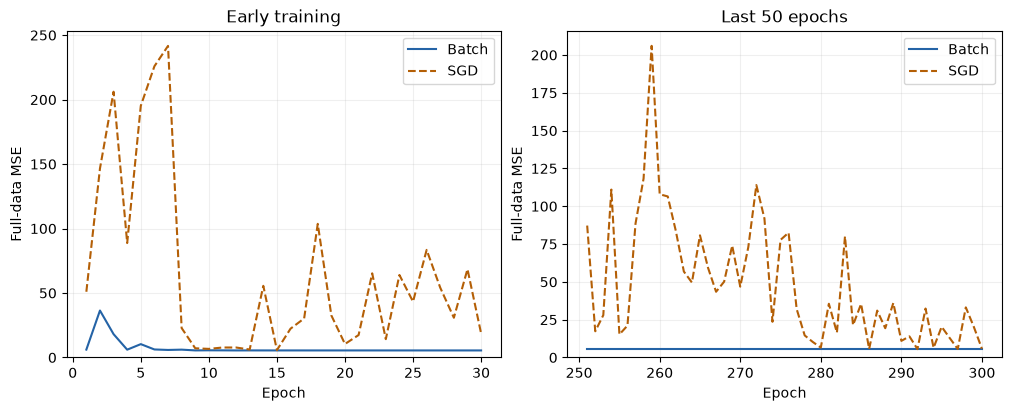

In [3]:
with torch.no_grad():
    sgd_predictions = sgd_net(data)
    sgd_final_mse = criterion(sgd_predictions, target).item()

print("Method     Updates    Final full-data MSE")
print("Batch      {:7d}    {:.6f}".format(300, batch_final_mse))
print("SGD        {:7d}    {:.6f}".format(sgd_updates, sgd_final_mse))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].plot(range(1, 31), batch_hist[:30], label="Batch", color="#2463a6")
axes[0].plot(range(1, 31), sgd_hist[:30], label="SGD", color="#b45f06", linestyle="--")
axes[0].set(title="Early training", xlabel="Epoch", ylabel="Full-data MSE")
axes[1].plot(range(251, 301), batch_hist[-50:], label="Batch", color="#2463a6")
axes[1].plot(range(251, 301), sgd_hist[-50:], label="SGD", color="#b45f06", linestyle="--")
axes[1].set(title="Last 50 epochs", xlabel="Epoch", ylabel="Full-data MSE")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.2)
    ax.legend()
plt.show()


## Training behavior

Batch loss oscillates initially, then settles near **5.476191**. SGD remains
noisy, with substantial fluctuations even late in training. Its final full-data
MSE is **5.776175**.

Batch training averages the gradients from all three points before each update,
balancing their competing effects. SGD updates using one point at a time; an
update that improves one point can worsen the others, causing the full-data
loss to fluctuate. Shuffling changes the order of these updates. The constant
learning rate keeps updates from shrinking automatically, and momentum carries
previous updates forward, which can amplify overshooting.
